In [9]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:

%pip install -r "/content/drive/MyDrive/Chili-ML-Results/requirements.txt"


In [11]:
import os
import sys
import random
import numpy as np
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Global Seed:", SEED)


Python: 3.13.15
TensorFlow: 2.21.0
Global Seed: 42


In [12]:

from pathlib import Path

dataset_folder = Path(
    "/content/drive/MyDrive/Chili-Leaf-Disease-Classification"
)

if dataset_folder.exists():
    print("Folder ditemukan!\n")
    print("Isi folder Google Drive:")

    for file in dataset_folder.iterdir():
        size_gb = file.stat().st_size / (1024 ** 3)
        print(f"{file.name} - {size_gb:.2f} GB")
else:
    print("Folder belum ditemukan. Periksa nama atau lokasinya di Google Drive.")


Folder belum ditemukan. Periksa nama atau lokasinya di Google Drive.


In [13]:

from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

if drive_path.exists():
    print("Google Drive berhasil ditemukan!\n")
    print("Daftar file dan folder:")

    for item in drive_path.iterdir():
        if item.is_dir():
            print(f"📁 {item.name}")
        else:
            print(f"📄 {item.name}")
else:
    print("Google Drive belum terhubung.")


Google Drive berhasil ditemukan!

Daftar file dan folder:
📁 Classroom
📄 PhotoGrid_1584872966133 (1).jpg
📄 something-just-like-this_coldplay-the-chainsmokers_ LaguAZ.net .mp3
📄 20200327_205654.jpg
📄 PhotoGrid_1584872966133.jpg
📄 Tugas Fisika (1).pdf
📄 Tugas Fisika.pdf
📄 I Kadek Deny Aditya Nanda (06) 8A.pdf
📄 IMG-20200721-WA0020.jpg
📄 InShot_20200805_122630615.jpg
📄 20200819_212755.jpg
📄 InShot_20200912_124839783.jpg
📄 20201004_205737.jpg
📄 20201007_151431.jpg
📄 20201007_214608 (3).jpg
📄 20201007_214608 (2).jpg
📄 20201007_214608 (1).jpg
📄 20201007_214608.jpg
📄 20201007_214616 (1).jpg
📄 20201007_214616.jpg
📄 InShot_20201010_214351212.jpg
📄 20201102_163137.jpg
📄 20201102_163142.jpg
📄 20201107_174355.jpg
📄 20201107_174403.jpg
📄 20201107_174330.jpg
📄 I kaden deny aditya nanda (06) IX A.pdf
📄 Diedit - 20201004_205737.jpg
📄 Dokumen dari Kadek Deny Aditya Nanda
📄 16260489262112598304085048263132.jpg
📄 20210712_081447 (1).jpg
📄 20210712_081444 (1).jpg
📄 20210712_081444.jpg
📄 20210712_081447.jpg

In [14]:

from pathlib import Path
import zipfile
import shutil

# Lokasi dataset di Google Drive
zip_path = Path(
    "/content/drive/MyDrive/Chili Leaf Disease Dataset Annotated Smartphone Im.zip"
)

if zip_path.exists():
    print("✅ Dataset berhasil ditemukan!")

    ukuran_gb = zip_path.stat().st_size / (1024 ** 3)
    print(f"Ukuran ZIP: {ukuran_gb:.2f} GB")

    # Membaca isi ZIP tanpa mengekstrak
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        files = zip_ref.infolist()

        total_gb = sum(f.file_size for f in files) / (1024 ** 3)
        print(f"Jumlah entri ZIP: {len(files)}")
        print(f"Ukuran setelah ekstraksi: {total_gb:.2f} GB")

        print("\nContoh isi dataset:")
        for file in files[:15]:
            print(file.filename)

    # Periksa penyimpanan sementara Colab
    disk = shutil.disk_usage("/content")
    free_gb = disk.free / (1024 ** 3)
    print(f"\nRuang kosong Colab: {free_gb:.2f} GB")

else:
    print("❌ File ZIP tidak ditemukan.")


✅ Dataset berhasil ditemukan!
Ukuran ZIP: 3.09 GB
Jumlah entri ZIP: 1550
Ukuran setelah ekstraksi: 3.11 GB

Contoh isi dataset:
Chili Leaf Disease Dataset Annotated Smartphone Im/dataset_image_metadata_full.csv
Chili Leaf Disease Dataset Annotated Smartphone Im/dataset_image_metadata_summary.csv
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG_20250615_165919_814.jpg
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG_20250615_165309_913.jpg
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG_20250615_161416_025.jpg
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG_20250615_162436_252.jpg
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG_20250615_162211_497.jpg
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG_20250615_162526_423.jpg
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG_20250615_162229_429.jpg
Chili Leaf Disease Dataset Annotated Smartphone Im/Anthracnose/IMG

In [15]:

import zipfile
from pathlib import Path
from tqdm.auto import tqdm

# Lokasi file ZIP di Google Drive
zip_path = Path(
    "/content/drive/MyDrive/Chili Leaf Disease Dataset Annotated Smartphone Im.zip"
)

# Lokasi ekstraksi di penyimpanan sementara Colab
extract_dir = Path("/content/chili_dataset")
extract_dir.mkdir(parents=True, exist_ok=True)

print("Memulai ekstraksi dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for file in tqdm(
        zip_ref.infolist(),
        desc="Extracting",
        unit="file"
    ):
        zip_ref.extract(file, extract_dir)

print("\n✅ Ekstraksi dataset berhasil!")
print("Lokasi:", extract_dir)


Memulai ekstraksi dataset...


Extracting:   0%|          | 0/1550 [00:00<?, ?file/s]


✅ Ekstraksi dataset berhasil!
Lokasi: /content/chili_dataset


In [16]:

from pathlib import Path

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

classes = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

total_images = 0

print("HASIL PEMERIKSAAN DATASET\n")

for class_name in classes:
    folder = dataset_path / class_name

    if folder.exists():
        images = [
            f for f in folder.rglob("*")
            if f.is_file()
            and f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        ]

        print(f"{class_name}: {len(images)} gambar")
        total_images += len(images)
    else:
        print(f"❌ Folder tidak ditemukan: {class_name}")

print("\nTotal gambar:", total_images)
print("Dataset siap diperiksa lebih lanjut." if total_images == 1548
      else "Jumlah berbeda, perlu pemeriksaan.")


HASIL PEMERIKSAAN DATASET

Anthracnose: 352 gambar
Cercospora Leaf Spot: 372 gambar
Fresh Leaf: 440 gambar
Leaf Curl Disease: 384 gambar

Total gambar: 1548
Dataset siap diperiksa lebih lanjut.


In [17]:

import pandas as pd
from pathlib import Path

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

metadata_files = [
    "dataset_image_metadata_full.csv",
    "dataset_image_metadata_summary.csv"
]

for filename in metadata_files:
    file_path = dataset_path / filename

    print("\n" + "=" * 60)
    print("FILE:", filename)
    print("=" * 60)

    if not file_path.exists():
        print("File tidak ditemukan!")
        continue

    try:
        df = pd.read_csv(file_path, encoding="utf-8-sig")
    except UnicodeDecodeError:
        df = pd.read_csv(file_path, encoding="latin1")

    print("Jumlah baris:", len(df))
    print("Jumlah kolom:", len(df.columns))

    print("\nNama kolom:")
    for column in df.columns:
        print("-", column)

    print("\nContoh 3 baris pertama:")
    print(df.head(3).to_string(index=False))

    print("\nJumlah nilai kosong:")
    print(df.isnull().sum().to_string())

print("\nPemeriksaan metadata selesai.")



FILE: dataset_image_metadata_full.csv
Jumlah baris: 1515
Jumlah kolom: 12

Nama kolom:
- class
- filename
- filepath
- file_size_mb
- width
- height
- megapixels
- aspect_ratio
- mode
- sharpness_score
- image_hash
- size_category

Contoh 3 baris pertama:
      class                    filename                                                                                                                filepath  file_size_mb  width  height  megapixels  aspect_ratio mode  sharpness_score           image_hash size_category
Anthracnose IMG_20250615_160619_644.jpg /content/drive/MyDrive/Chili Leaf Project/Classification/Classification Dataset/Anthracnose/IMG_20250615_160619_644.jpg      1.136132   1728    3936    6.801408      0.439024  RGB         9.000104  2104078762324702082        1-2 MB
Anthracnose IMG_20250615_160624_405.jpg /content/drive/MyDrive/Chili Leaf Project/Classification/Classification Dataset/Anthracnose/IMG_20250615_160624_405.jpg      1.066537   3936    1728    6.80140

In [18]:

import pandas as pd
from pathlib import Path
from collections import Counter

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

metadata_path = dataset_path / "dataset_image_metadata_full.csv"

# Baca metadata
df = pd.read_csv(metadata_path, encoding="utf-8-sig")

df["class"] = df["class"].astype(str).str.strip()
df["filename"] = df["filename"].astype(str).str.strip()

classes = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

extensions = {".jpg", ".jpeg", ".png", ".webp"}

# Daftar gambar asli dalam folder
actual_files = []

for class_name in classes:
    folder = dataset_path / class_name

    for image_file in folder.rglob("*"):
        if image_file.is_file() and image_file.suffix.lower() in extensions:
            actual_files.append((class_name, image_file.name))

# Daftar gambar dari metadata
metadata_files = list(zip(df["class"], df["filename"]))

actual_set = set(actual_files)
metadata_set = set(metadata_files)

# Bandingkan data
not_in_metadata = sorted(actual_set - metadata_set)
not_in_folder = sorted(metadata_set - actual_set)

actual_counts = Counter(x[0] for x in actual_files)
metadata_counts = Counter(x[0] for x in metadata_files)

print("PERBANDINGAN DATASET DAN METADATA")
print("=" * 60)

for class_name in classes:
    print(f"\n{class_name}")
    print("  Gambar asli :", actual_counts[class_name])
    print("  Metadata    :", metadata_counts[class_name])

print("\n" + "=" * 60)
print("Total gambar asli :", len(actual_files))
print("Total metadata    :", len(metadata_files))

print("\nGambar belum tercatat di metadata:")
print(len(not_in_metadata))

for item in not_in_metadata[:10]:
    print(" +", item)

print("\nGambar tercatat di metadata tetapi tidak ditemukan:")
print(len(not_in_folder))

for item in not_in_folder[:10]:
    print(" -", item)

print("\nBaris metadata dengan kelas dan filename berulang:")
print(df.duplicated(subset=["class", "filename"]).sum())

print("\nPemeriksaan selesai.")


PERBANDINGAN DATASET DAN METADATA

Anthracnose
  Gambar asli : 352
  Metadata    : 347

Cercospora Leaf Spot
  Gambar asli : 372
  Metadata    : 367

Fresh Leaf
  Gambar asli : 440
  Metadata    : 432

Leaf Curl Disease
  Gambar asli : 384
  Metadata    : 369

Total gambar asli : 1548
Total metadata    : 1515

Gambar belum tercatat di metadata:
33
 + ('Anthracnose', 'IMG_20250615_160909_247.jpg')
 + ('Anthracnose', 'IMG_20250615_160913_178.jpg')
 + ('Anthracnose', 'IMG_20250615_160914_144.jpg')
 + ('Anthracnose', 'IMG_20250615_160919_012.jpg')
 + ('Anthracnose', 'IMG_20250615_163037_605.jpg')
 + ('Cercospora Leaf Spot', 'IMG_20250615_162249.jpg')
 + ('Cercospora Leaf Spot', 'IMG_20250615_162301.jpg')
 + ('Cercospora Leaf Spot', 'IMG_20250615_163844.jpg')
 + ('Cercospora Leaf Spot', 'IMG_20250615_164138.jpg')
 + ('Cercospora Leaf Spot', 'IMG_20250615_164240.jpg')

Gambar tercatat di metadata tetapi tidak ditemukan:
0

Baris metadata dengan kelas dan filename berulang:
0

Pemeriksaan sel

In [19]:

from pathlib import Path
from PIL import Image
import pandas as pd

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

metadata = pd.read_csv(
    dataset_path / "dataset_image_metadata_full.csv"
)

# Daftar gambar yang tercatat pada metadata
metadata_files = set(
    zip(
        metadata["class"].str.strip(),
        metadata["filename"].str.strip()
    )
)

classes = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

extensions = {".jpg", ".jpeg", ".png", ".webp"}

additional_images = []
invalid_images = []

print("VALIDASI GAMBAR TAMBAHAN")
print("=" * 50)

for class_name in classes:
    folder = dataset_path / class_name

    for image_path in folder.rglob("*"):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in extensions:
            continue

        key = (class_name, image_path.name)

        if key not in metadata_files:
            additional_images.append(image_path)

            try:
                with Image.open(image_path) as img:
                    img.verify()

                with Image.open(image_path) as img:
                    width, height = img.size

                print(
                    f"VALID | {class_name} | "
                    f"{image_path.name} | {width}x{height}"
                )

            except Exception as e:
                invalid_images.append(
                    (str(image_path), str(e))
                )

print("\n" + "=" * 50)
print("Total gambar tambahan:", len(additional_images))
print("Gambar gagal validasi:", len(invalid_images))

if not invalid_images:
    print("✅ Semua gambar tambahan dapat dibaca!")
else:
    print("\nGambar bermasalah:")
    for path, error in invalid_images:
        print(path, error)


VALIDASI GAMBAR TAMBAHAN
VALID | Anthracnose | IMG_20250615_160909_247.jpg | 1728x3936
VALID | Anthracnose | IMG_20250615_160913_178.jpg | 1728x3936
VALID | Anthracnose | IMG_20250615_163037_605.jpg | 3936x1728
VALID | Anthracnose | IMG_20250615_160914_144.jpg | 1728x3936
VALID | Anthracnose | IMG_20250615_160919_012.jpg | 3936x1728
VALID | Cercospora Leaf Spot | IMG_20250615_163844.jpg | 4080x3072
VALID | Cercospora Leaf Spot | IMG_20250615_162301.jpg | 4080x3072
VALID | Cercospora Leaf Spot | IMG_20250615_164138.jpg | 4080x3072
VALID | Cercospora Leaf Spot | IMG_20250615_162249.jpg | 4080x3072
VALID | Cercospora Leaf Spot | IMG_20250615_164240.jpg | 4080x3072
VALID | Fresh Leaf | IMG_20250615_171830.jpg | 4080x3072
VALID | Fresh Leaf | IMG_20250615_171749.jpg | 4080x3072
VALID | Fresh Leaf | IMG_20250615_171908.jpg | 4080x3072
VALID | Fresh Leaf | IMG_20250615_165634.jpg | 4000x3000
VALID | Fresh Leaf | IMG_20250615_171943.jpg | 4080x3072
VALID | Fresh Leaf | IMG_20250615_172014.jpg 

In [20]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from collections import defaultdict
import hashlib

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

classes = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

extensions = {".jpg", ".jpeg", ".png", ".webp"}

hash_groups = defaultdict(list)
invalid_images = []
total_checked = 0

# Kumpulkan semua gambar
image_files = []

for class_name in classes:
    folder = dataset_path / class_name
    image_files.extend(
        path for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in extensions
    )

print("MEMERIKSA SELURUH DATASET")
print("=" * 50)

for image_path in tqdm(image_files, desc="Validasi gambar"):
    total_checked += 1

    try:
        # Periksa apakah gambar valid
        with Image.open(image_path) as img:
            img.verify()

        # Hitung hash file untuk deteksi duplikat identik
        sha256 = hashlib.sha256()

        with open(image_path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha256.update(chunk)

        hash_groups[sha256.hexdigest()].append(image_path)

    except Exception as e:
        invalid_images.append((str(image_path), str(e)))

# Kelompok file yang identik
duplicate_groups = [
    paths for paths in hash_groups.values()
    if len(paths) > 1
]

duplicate_extras = sum(
    len(group) - 1 for group in duplicate_groups
)

print("\nHASIL PEMERIKSAAN")
print("=" * 50)
print("Total gambar diperiksa:", total_checked)
print("Gambar rusak:", len(invalid_images))
print("Kelompok duplikat identik:", len(duplicate_groups))
print("Jumlah salinan duplikat:", duplicate_extras)

print("\nContoh duplikat (jika ada):")
for group in duplicate_groups[:5]:
    print("---")
    for path in group:
        print(path.parent.name, "/", path.name)

print("\nGambar rusak (jika ada):")
for path, error in invalid_images[:10]:
    print(path, ":", error)

print("\n✅ Pemeriksaan selesai!")


MEMERIKSA SELURUH DATASET


Validasi gambar:   0%|          | 0/1548 [00:00<?, ?it/s]


HASIL PEMERIKSAAN
Total gambar diperiksa: 1548
Gambar rusak: 0
Kelompok duplikat identik: 0
Jumlah salinan duplikat: 0

Contoh duplikat (jika ada):

Gambar rusak (jika ada):

✅ Pemeriksaan selesai!


In [21]:


from pathlib import Path
from PIL import Image, ImageOps
import imagehash
import pandas as pd
from tqdm.auto import tqdm

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

classes = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

extensions = {".jpg", ".jpeg", ".png", ".webp"}

# Kumpulkan daftar gambar
image_paths = []

for class_name in classes:
    folder = dataset_path / class_name
    image_paths.extend(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )

image_paths = sorted(image_paths)

# Hitung perceptual hash
records = []

print("Menghitung perceptual hash...")

for path in tqdm(image_paths):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img)
        phash = imagehash.phash(img)

    records.append({
        "class": path.parent.name,
        "filename": path.name,
        "path": str(path),
        "hash": int(str(phash), 16)
    })

# Bandingkan pasangan gambar
# Jarak <= 6 hanya digunakan sebagai kandidat pemeriksaan
threshold = 6
candidates = []

print("\nMencari gambar yang hampir sama...")

for i in range(len(records)):
    for j in range(i + 1, len(records)):
        distance = (
            records[i]["hash"] ^ records[j]["hash"]
        ).bit_count()

        if distance <= threshold:
            candidates.append({
                "class_1": records[i]["class"],
                "image_1": records[i]["filename"],
                "class_2": records[j]["class"],
                "image_2": records[j]["filename"],
                "distance": distance
            })

df_similar = pd.DataFrame(candidates)

print("\nHASIL PEMERIKSAAN KEMIRIPAN")
print("=" * 50)
print("Total gambar:", len(records))
print("Kandidat pasangan mirip:", len(candidates))

if not df_similar.empty:
    df_similar = df_similar.sort_values("distance")

    print("\n20 pasangan paling mirip:")
    print(df_similar.head(20).to_string(index=False))

    df_similar.to_csv(
        "/content/near_duplicate_candidates.csv",
        index=False
    )
else:
    print("Tidak ditemukan pasangan dengan jarak pHash <= 6.")

print("\n✅ Pemeriksaan selesai!")


Menghitung perceptual hash...


  0%|          | 0/1548 [00:00<?, ?it/s]


Mencari gambar yang hampir sama...

HASIL PEMERIKSAAN KEMIRIPAN
Total gambar: 1548
Kandidat pasangan mirip: 226

20 pasangan paling mirip:
          class_1                                    image_1           class_2                              image_2  distance
      Anthracnose       IMG_20250615_165121472_BURST0002.jpg       Anthracnose IMG_20250615_165121472_BURST0003.jpg         0
      Anthracnose                IMG_20250615_165837_124.jpg       Anthracnose          IMG_20250615_165837_309.jpg         0
      Anthracnose                IMG_20250615_165832_846.jpg       Anthracnose          IMG_20250615_165833_243.jpg         0
      Anthracnose                IMG_20250615_165829_580.jpg       Anthracnose          IMG_20250615_165829_847.jpg         0
Leaf Curl Disease                    IMG_20250620_145035.jpg Leaf Curl Disease              IMG_20250620_145036.jpg         0
      Anthracnose                IMG_20250615_161432_775.jpg       Anthracnose          IMG_20250615_161

ANALISIS PASANGAN GAMBAR
Total pasangan mirip: 226
Pasangan beda kelas: 88
Pasangan kelas sama: 138

Contoh pasangan beda kelas:
             class_1                              image_1              class_2                 image_2  distance
         Anthracnose IMG_20250615_165121472_BURST0016.jpg           Fresh Leaf IMG_20250615_170958.jpg         2
         Anthracnose IMG_20250615_165121472_BURST0012.jpg Cercospora Leaf Spot IMG_20250615_163759.jpg         4
         Anthracnose IMG_20250615_165121472_BURST0013.jpg           Fresh Leaf IMG_20250615_171952.jpg         4
         Anthracnose IMG_20250615_165121472_BURST0012.jpg Cercospora Leaf Spot IMG_20250615_162942.jpg         4
         Anthracnose IMG_20250615_165121472_BURST0011.jpg Cercospora Leaf Spot IMG_20250615_163759.jpg         4
Cercospora Leaf Spot              IMG_20250615_165017.jpg           Fresh Leaf IMG_20250615_171856.jpg         4
Cercospora Leaf Spot              IMG_20250615_164726.jpg           Fresh Leaf I

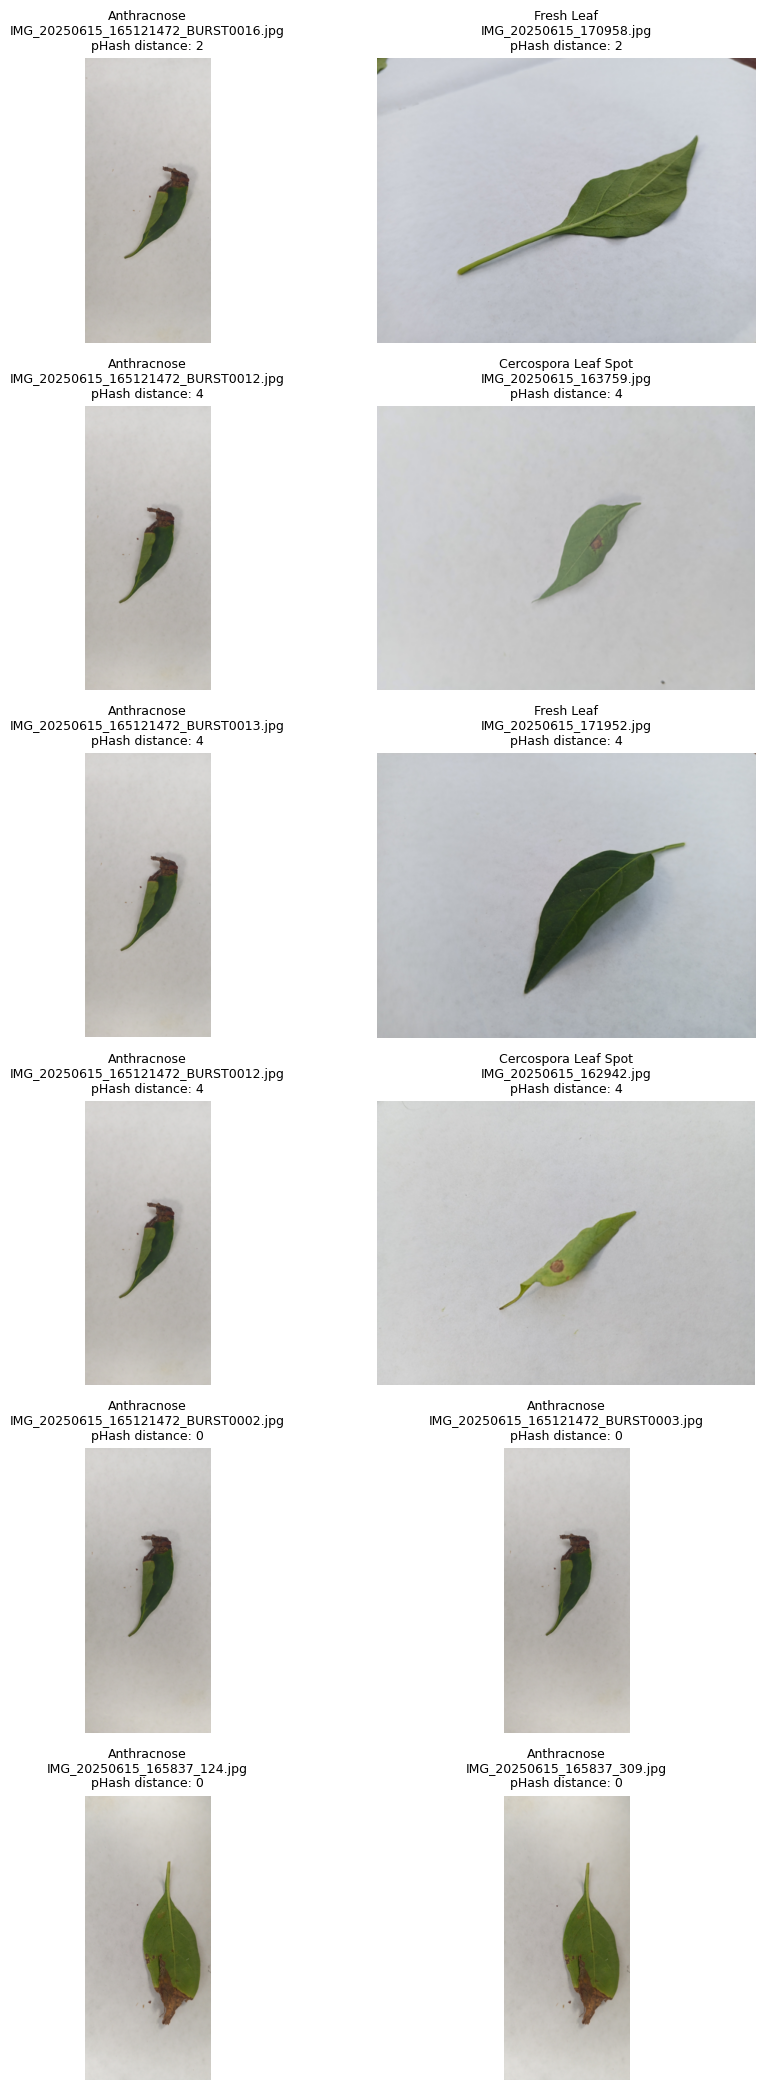

In [22]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# Pisahkan pasangan dengan kelas sama dan berbeda
cross_class = df_similar[
    df_similar["class_1"] != df_similar["class_2"]
].sort_values("distance")

same_class = df_similar[
    df_similar["class_1"] == df_similar["class_2"]
].sort_values("distance")

print("ANALISIS PASANGAN GAMBAR")
print("=" * 50)

print("Total pasangan mirip:", len(df_similar))
print("Pasangan beda kelas:", len(cross_class))
print("Pasangan kelas sama:", len(same_class))

print("\nContoh pasangan beda kelas:")
print(cross_class.head(10).to_string(index=False))

# Pilih contoh untuk pemeriksaan visual
review = pd.concat([
    cross_class.head(4),
    same_class.head(2)
], ignore_index=True)

# Peta lokasi gambar dari pemeriksaan sebelumnya
image_lookup = {
    (p.parent.name, p.name): p
    for p in image_paths
}

if not review.empty:
    fig, axes = plt.subplots(
        len(review), 2,
        figsize=(10, 3.5 * len(review)),
        squeeze=False
    )

    for i, row in review.iterrows():
        pairs = [
            (row["class_1"], row["image_1"]),
            (row["class_2"], row["image_2"])
        ]

        for j, (class_name, filename) in enumerate(pairs):
            ax = axes[i, j]

            path = image_lookup.get(
                (class_name, filename)
            )

            if path is not None:
                with Image.open(path) as img:
                    img = ImageOps.exif_transpose(img)
                    img = img.convert("RGB")
                    img.thumbnail((500, 500))
                    ax.imshow(img)

            ax.set_title(
                f"{class_name}\n"
                f"{filename}\n"
                f"pHash distance: {row['distance']}",
                fontsize=9
            )
            ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("Tidak ada kandidat untuk ditampilkan.")


In [23]:

import re
import pandas as pd
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import StratifiedGroupKFold

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

classes = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

extensions = {".jpg", ".jpeg", ".png", ".webp"}

# 1. Kumpulkan semua gambar
paths = sorted([
    p
    for cls in classes
    for p in (dataset_path / cls).rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
])

assert len(paths) == 1548, "Jumlah gambar tidak sesuai!"

lookup = {
    (p.parent.name, p.name): i
    for i, p in enumerate(paths)
}

# 2. Buat kelompok gambar menggunakan Union-Find
parent = list(range(len(paths)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

# Kelompokkan foto BURST dari rangkaian yang sama
burst_groups = defaultdict(list)

for i, p in enumerate(paths):
    match = re.match(r"(.+)_BURST\d+", p.stem)

    if match:
        key = (p.parent.name, match.group(1))
        burst_groups[key].append(i)

for indices in burst_groups.values():
    for i in indices[1:]:
        union(indices[0], i)

# Tambahkan pasangan sangat mirip dari kelas yang sama
similar = pd.read_csv(
    "/content/near_duplicate_candidates.csv"
)

for row in similar.itertuples(index=False):
    if row.class_1 != row.class_2:
        continue

    if row.distance > 2:
        continue

    a = lookup.get((row.class_1, row.image_1))
    b = lookup.get((row.class_2, row.image_2))

    if a is not None and b is not None:
        union(a, b)

# 3. Buat manifest dataset
manifest = pd.DataFrame({
    "relative_path": [
        str(p.relative_to(dataset_path)) for p in paths
    ],
    "class": [p.parent.name for p in paths],
    "group": [find(i) for i in range(len(paths))]
})

# 4. Split dengan mempertahankan kelompok
splitter_test = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

trainval_idx, test_idx = next(
    splitter_test.split(
        manifest,
        manifest["class"],
        groups=manifest["group"]
    )
)

trainval = manifest.iloc[trainval_idx]

splitter_val = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=43
)

train_idx, val_idx = next(
    splitter_val.split(
        trainval,
        trainval["class"],
        groups=trainval["group"]
    )
)

manifest["split"] = "test"
manifest.loc[trainval.iloc[train_idx].index, "split"] = "train"
manifest.loc[trainval.iloc[val_idx].index, "split"] = "val"

# 5. Periksa hasil
print("HASIL PEMBAGIAN DATASET")
print("=" * 55)

print(pd.crosstab(
    manifest["class"],
    manifest["split"]
).reindex(columns=["train", "val", "test"], fill_value=0))

print("\nTotal per bagian:")
print(manifest["split"].value_counts())

print("\nJumlah kelompok:", manifest["group"].nunique())

# Pastikan satu kelompok tidak tersebar ke beberapa split
leaking_groups = (
    manifest.groupby("group")["split"].nunique() > 1
).sum()

print("Kelompok yang terpisah:", leaking_groups)

assert leaking_groups == 0

# 6. Simpan pembagian secara permanen di Drive
output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "dataset_split_manifest.csv"

manifest.to_csv(output_file, index=False)

print("\nManifest tersimpan di:", output_file)
print("✅ Pembagian awal selesai!")


HASIL PEMBAGIAN DATASET
split                 train  val  test
class                                 
Anthracnose             274   40    38
Cercospora Leaf Spot    274   50    48
Fresh Leaf              315   62    63
Leaf Curl Disease       274   54    56

Total per bagian:
split
train    1137
val       206
test      205
Name: count, dtype: int64

Jumlah kelompok: 1516
Kelompok yang terpisah: 0

Manifest tersimpan di: /content/drive/MyDrive/Chili-ML-Results/dataset_split_manifest.csv
✅ Pembagian awal selesai!


In [24]:

import pandas as pd
from pathlib import Path

# Baca pembagian dataset yang sudah disimpan
manifest = pd.read_csv(
    "/content/drive/MyDrive/Chili-ML-Results/dataset_split_manifest.csv"
)

# Baca hasil pemeriksaan pHash sebelumnya
similar = pd.read_csv(
    "/content/near_duplicate_candidates.csv"
)

manifest["filename"] = manifest["relative_path"].apply(
    lambda x: Path(x).name
)

# Peta gambar ke bagian dataset
split_lookup = {
    (row["class"], row["filename"]): row["split"]
    for _, row in manifest.iterrows()
}

cross_split = []

for row in similar.itertuples(index=False):

    # Fokus pada pasangan dari kelas yang sama
    if row.class_1 != row.class_2:
        continue

    split_a = split_lookup.get(
        (row.class_1, row.image_1)
    )

    split_b = split_lookup.get(
        (row.class_2, row.image_2)
    )

    if split_a is None or split_b is None:
        continue

    if split_a != split_b:
        cross_split.append({
            "class": row.class_1,
            "image_1": row.image_1,
            "image_2": row.image_2,
            "distance": row.distance,
            "split_1": split_a,
            "split_2": split_b
        })

df_cross = pd.DataFrame(cross_split)

print("AUDIT PEMBAGIAN DATASET")
print("=" * 55)

print("Total gambar:", len(manifest))
print("Jumlah kelompok:", manifest["group"].nunique())

print("\nPasangan mirip kelas sama:")
print(len(similar[
    similar["class_1"] == similar["class_2"]
]))

print("\nPasangan mirip yang melewati batas split:")
print(len(df_cross))

if not df_cross.empty:
    print("\nDistribusi berdasarkan jarak pHash:")
    print(
        df_cross["distance"]
        .value_counts()
        .sort_index()
    )

    print("\nContoh pasangan yang perlu ditinjau:")
    print(
        df_cross.sort_values("distance")
        .head(15)
        .to_string(index=False)
    )
else:
    print("Tidak ditemukan kandidat lintas split.")

print("\n✅ Audit selesai!")


AUDIT PEMBAGIAN DATASET
Total gambar: 1548
Jumlah kelompok: 1516

Pasangan mirip kelas sama:
138

Pasangan mirip yang melewati batas split:
30

Distribusi berdasarkan jarak pHash:
distance
4     6
6    24
Name: count, dtype: int64

Contoh pasangan yang perlu ditinjau:
               class                     image_1                     image_2  distance split_1 split_2
          Fresh Leaf     IMG_20250615_165420.jpg     IMG_20250615_165422.jpg         4   train     val
Cercospora Leaf Spot     IMG_20250615_161259.jpg     IMG_20250615_164125.jpg         4     val   train
Cercospora Leaf Spot     IMG_20250615_162105.jpg     IMG_20250615_163110.jpg         4     val    test
         Anthracnose IMG_20250615_164442_049.jpg IMG_20250615_164443_834.jpg         4   train     val
         Anthracnose IMG_20250615_162939_408.jpg IMG_20250615_162940_903.jpg         4    test   train
          Fresh Leaf     IMG_20250615_171404.jpg     IMG_20250615_172050.jpg         4     val    test
         A

Total kandidat lintas split: 30
Pasangan dengan selisih waktu <= 5 detik: 6


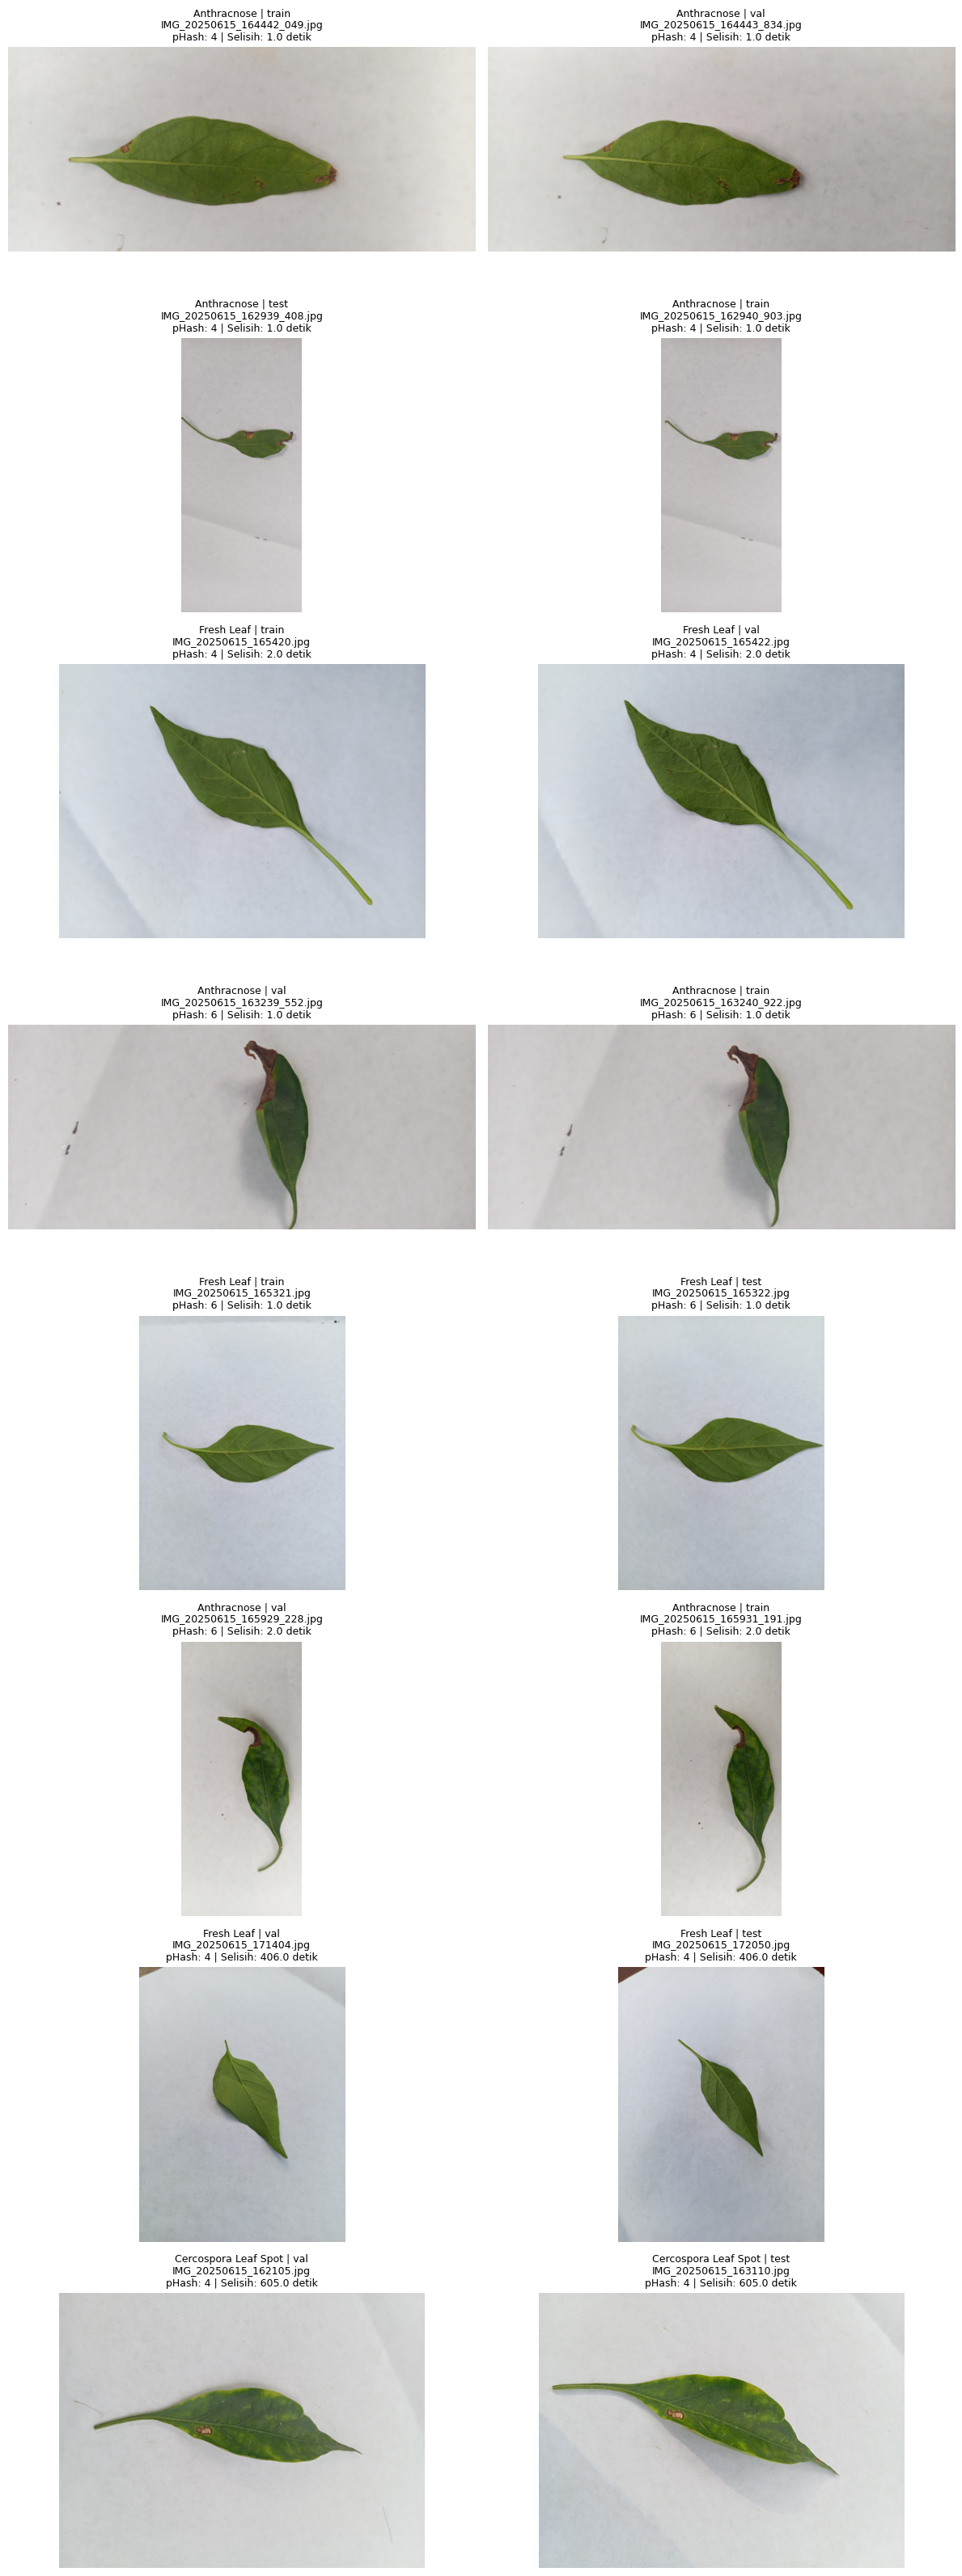

In [25]:

import re
import matplotlib.pyplot as plt
from datetime import datetime
from PIL import Image, ImageOps

def get_capture_time(filename):
    match = re.search(
        r"IMG_(\d{8})_(\d{6})",
        filename
    )

    if not match:
        return None

    return datetime.strptime(
        match.group(1) + match.group(2),
        "%Y%m%d%H%M%S"
    )

def time_difference(row):
    t1 = get_capture_time(row["image_1"])
    t2 = get_capture_time(row["image_2"])

    if t1 is None or t2 is None:
        return float("inf")

    return abs((t1 - t2).total_seconds())

# Gunakan hasil audit sebelumnya
review = df_cross.copy()

review["selisih_detik"] = review.apply(
    time_difference,
    axis=1
)

review["waktu_berdekatan"] = (
    review["selisih_detik"] <= 5
)

# Prioritaskan foto berdekatan waktunya
review = review.sort_values(
    ["waktu_berdekatan", "distance", "selisih_detik"],
    ascending=[False, True, True]
)

print("Total kandidat lintas split:", len(review))
print(
    "Pasangan dengan selisih waktu <= 5 detik:",
    review["waktu_berdekatan"].sum()
)

# Tampilkan 8 pasangan pertama
sample = review.head(8)

fig, axes = plt.subplots(
    len(sample),
    2,
    figsize=(12, 4 * len(sample)),
    squeeze=False
)

for i, (_, row) in enumerate(sample.iterrows()):
    pairs = [
        (row["class"], row["image_1"], row["split_1"]),
        (row["class"], row["image_2"], row["split_2"])
    ]

    for j, (cls, filename, split) in enumerate(pairs):
        path = dataset_path / cls / filename

        with Image.open(path) as img:
            img = ImageOps.exif_transpose(img)
            img = img.convert("RGB")
            img.thumbnail((550, 550))

            axes[i, j].imshow(img)

        axes[i, j].set_title(
            f"{cls} | {split}\n"
            f"{filename}\n"
            f"pHash: {row['distance']} | "
            f"Selisih: {row['selisih_detik']:.1f} detik",
            fontsize=9
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [26]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
import shutil

# Lokasi hasil pemeriksaan sebelumnya
output_dir = Path("/content/drive/MyDrive/Chili-ML-Results")

manifest = pd.read_csv(
    output_dir / "dataset_split_manifest.csv"
).reset_index(drop=True)

similar = pd.read_csv(
    "/content/near_duplicate_candidates.csv"
)

# Peta setiap gambar ke indeks
lookup = {
    (row["class"], Path(row["relative_path"]).name): i
    for i, row in manifest.iterrows()
}

assert len(lookup) == len(manifest), "Ada nama gambar ambigu!"

# Union-Find untuk menggabungkan kelompok
parent = list(range(len(manifest)))

def find(x):
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

# 1. Pertahankan kelompok lama
for _, group_df in manifest.groupby("group"):
    indices = group_df.index.tolist()
    for i in indices[1:]:
        union(indices[0], i)

# 2. Gabungkan kandidat foto mirip dalam kelas sama
merged_pairs = 0

for row in similar.itertuples(index=False):
    if row.class_1 != row.class_2:
        continue

    if row.distance > 6:
        continue

    a = lookup.get((row.class_1, row.image_1))
    b = lookup.get((row.class_2, row.image_2))

    if a is not None and b is not None:
        union(a, b)
        merged_pairs += 1

# 3. Buat identitas kelompok baru
root_ids = [find(i) for i in range(len(manifest))]
group_ids = {
    root: idx for idx, root in enumerate(sorted(set(root_ids)))
}

manifest["group"] = [
    group_ids[root] for root in root_ids
]

# Pastikan satu kelompok hanya memiliki satu kelas
assert (
    manifest.groupby("group")["class"].nunique().max()
    == 1
), "Terdapat kelompok dengan label berbeda!"

# 4. Pembagian berdasarkan kelompok
splitter_test = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

trainval_idx, test_idx = next(
    splitter_test.split(
        manifest,
        manifest["class"],
        groups=manifest["group"]
    )
)

trainval = manifest.iloc[trainval_idx]

splitter_val = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=43
)

train_idx, val_idx = next(
    splitter_val.split(
        trainval,
        trainval["class"],
        groups=trainval["group"]
    )
)

manifest["split"] = "test"

manifest.loc[
    trainval.iloc[train_idx].index, "split"
] = "train"

manifest.loc[
    trainval.iloc[val_idx].index, "split"
] = "val"

# 5. Audit ulang
leaking_groups = (
    manifest.groupby("group")["split"].nunique() > 1
).sum()

split_lookup = {
    (row["class"], Path(row["relative_path"]).name): row["split"]
    for _, row in manifest.iterrows()
}

cross_split = 0

for row in similar.itertuples(index=False):
    if row.class_1 != row.class_2 or row.distance > 6:
        continue

    a = split_lookup.get((row.class_1, row.image_1))
    b = split_lookup.get((row.class_2, row.image_2))

    if a is not None and b is not None and a != b:
        cross_split += 1

print("HASIL PEMBAGIAN DATASET V2")
print("=" * 55)

print(pd.crosstab(
    manifest["class"],
    manifest["split"]
).reindex(columns=["train", "val", "test"], fill_value=0))

print("\nTotal setiap bagian:")
print(manifest["split"].value_counts())

print("\nTotal gambar:", len(manifest))
print("Jumlah kelompok baru:", manifest["group"].nunique())
print("Pasangan mirip yang dikelompokkan:", merged_pairs)
print("Kelompok terpisah:", leaking_groups)
print("Kandidat mirip lintas split:", cross_split)

assert leaking_groups == 0
assert cross_split == 0

# 6. Simpan manifest baru, tanpa menimpa versi pertama
output_file = output_dir / "dataset_split_manifest_v2.csv"

manifest.to_csv(output_file, index=False)

# Simpan juga hasil audit pHash secara permanen
shutil.copy2(
    "/content/near_duplicate_candidates.csv",
    output_dir / "near_duplicate_candidates.csv"
)

print("\nManifest V2 disimpan di:", output_file)
print("✅ Pembagian dataset V2 selesai!")


HASIL PEMBAGIAN DATASET V2
split                 train  val  test
class                                 
Anthracnose             269   44    39
Cercospora Leaf Spot    273   49    50
Fresh Leaf              317   61    62
Leaf Curl Disease       277   53    54

Total setiap bagian:
split
train    1136
val       207
test      205
Name: count, dtype: int64

Total gambar: 1548
Jumlah kelompok baru: 1443
Pasangan mirip yang dikelompokkan: 138
Kelompok terpisah: 0
Kandidat mirip lintas split: 0

Manifest V2 disimpan di: /content/drive/MyDrive/Chili-ML-Results/dataset_split_manifest_v2.csv
✅ Pembagian dataset V2 selesai!


In [27]:

import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))


TensorFlow Version: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [28]:

from pathlib import Path

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

manifest_path = Path(
    "/content/drive/MyDrive/Chili-ML-Results/"
    "dataset_split_manifest_v2.csv"
)

print("Dataset tersedia:", dataset_path.exists())
print("Manifest V2 tersedia:", manifest_path.exists())


Dataset tersedia: True
Manifest V2 tersedia: True


In [29]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:

from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im.zip"
)

manifest_path = Path(
    "/content/drive/MyDrive/Chili-ML-Results/"
    "dataset_split_manifest_v2.csv"
)

dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

print("PEMERIKSAAN FILE")
print("=" * 40)

print("ZIP Dataset:", zip_path.exists())
print("Manifest V2:", manifest_path.exists())
print("Folder ekstraksi:", dataset_path.exists())


PEMERIKSAAN FILE
ZIP Dataset: True
Manifest V2: True
Folder ekstraksi: True


In [31]:

import zipfile
from pathlib import Path
from tqdm.auto import tqdm

zip_path = Path(
    "/content/drive/MyDrive/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im.zip"
)

extract_dir = Path("/content/chili_dataset")

dataset_path = (
    extract_dir /
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

extract_dir.mkdir(parents=True, exist_ok=True)

print("Memulai ekstraksi ulang dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for file in tqdm(
        zip_ref.infolist(),
        desc="Extracting",
        unit="file"
    ):
        zip_ref.extract(file, extract_dir)

print("\n✅ Ekstraksi selesai!")
print("Dataset tersedia:", dataset_path.exists())
print("Manifest V2 tersedia:", manifest_path.exists())


Memulai ekstraksi ulang dataset...


Extracting:   0%|          | 0/1550 [00:00<?, ?file/s]


✅ Ekstraksi selesai!
Dataset tersedia: True
Manifest V2 tersedia: True


In [32]:

from pathlib import Path
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import pandas as pd
import json

# Lokasi dataset asli
dataset_path = Path(
    "/content/chili_dataset/"
    "Chili Leaf Disease Dataset Annotated Smartphone Im"
)

# Manifest V2
manifest_path = Path(
    "/content/drive/MyDrive/Chili-ML-Results/"
    "dataset_split_manifest_v2.csv"
)

# Folder untuk gambar hasil preprocessing
processed_dir = Path("/content/chili_processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Urutan kelas untuk ML dan Android
class_names = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

IMG_SIZE = (224, 224)

manifest = pd.read_csv(manifest_path)

assert len(manifest) == 1548
assert dataset_path.exists()

processed_count = 0
failed_images = []

print("Memulai preprocessing gambar...")

for row in tqdm(
    manifest.itertuples(index=False),
    total=len(manifest),
    desc="Preprocessing"
):
    relative_path = Path(row.relative_path)

    source = dataset_path / relative_path
    destination = (
        processed_dir / relative_path
    ).with_suffix(".jpg")

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    try:
        with Image.open(source) as img:
            # Memperbaiki orientasi gambar
            img = ImageOps.exif_transpose(img)
            img = img.convert("RGB")

            # Resize tanpa mengubah proporsi daun
            img = ImageOps.pad(
                img,
                IMG_SIZE,
                method=Image.Resampling.LANCZOS,
                color=(255, 255, 255)
            )

            # Simpan dengan kualitas tinggi
            img.save(
                destination,
                format="JPEG",
                quality=95
            )

        processed_count += 1

    except Exception as e:
        failed_images.append(
            (str(source), str(e))
        )

# Simpan urutan kelas secara permanen
output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)
output_dir.mkdir(parents=True, exist_ok=True)

with open(
    output_dir / "class_names.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        class_names,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nHASIL PREPROCESSING")
print("=" * 50)
print("Total gambar:", len(manifest))
print("Berhasil diproses:", processed_count)
print("Gambar gagal:", len(failed_images))
print("Ukuran input:", IMG_SIZE)
print("Folder hasil:", processed_dir)

if failed_images:
    print("\nContoh gambar bermasalah:")
    for item in failed_images[:5]:
        print(item)
else:
    print("\n✅ Semua gambar berhasil diproses!")


Memulai preprocessing gambar...


Preprocessing:   0%|          | 0/1548 [00:00<?, ?it/s]


HASIL PREPROCESSING
Total gambar: 1548
Berhasil diproses: 1548
Gambar gagal: 0
Ukuran input: (224, 224)
Folder hasil: /content/chili_processed

✅ Semua gambar berhasil diproses!


In [33]:

from pathlib import Path
from zipfile import ZipFile, ZIP_STORED
import shutil
from tqdm.auto import tqdm

processed_dir = Path("/content/chili_processed")

backup_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)
backup_dir.mkdir(parents=True, exist_ok=True)

temp_zip = Path("/content/chili_processed_224.zip")
drive_zip = backup_dir / "chili_processed_224.zip"

images = sorted(processed_dir.rglob("*.jpg"))

assert len(images) == 1548, "Jumlah gambar tidak sesuai!"

print("Membuat backup preprocessing...")

with ZipFile(temp_zip, "w", compression=ZIP_STORED) as zf:
    for image_path in tqdm(images, desc="Backup"):
        zf.write(
            image_path,
            arcname=str(image_path.relative_to(processed_dir))
        )

# Salin ZIP ke Google Drive
shutil.copy2(temp_zip, drive_zip)

print("\n✅ Backup berhasil!")
print("Jumlah gambar:", len(images))
print("Lokasi:", drive_zip)
print(
    "Ukuran ZIP:",
    round(drive_zip.stat().st_size / (1024 ** 2), 2),
    "MB"
)


Membuat backup preprocessing...


Backup:   0%|          | 0/1548 [00:00<?, ?it/s]


✅ Backup berhasil!
Jumlah gambar: 1548
Lokasi: /content/drive/MyDrive/Chili-ML-Results/chili_processed_224.zip
Ukuran ZIP: 14.29 MB


In [34]:

import tensorflow as tf
import pandas as pd
from pathlib import Path

tf.keras.utils.set_random_seed(42)

processed_dir = Path("/content/chili_processed")

manifest = pd.read_csv(
    "/content/drive/MyDrive/Chili-ML-Results/"
    "dataset_split_manifest_v2.csv"
)

class_names = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

class_to_index = {
    name: i for i, name in enumerate(class_names)
}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.ensure_shape(image, [224, 224, 3])
    image = tf.cast(image, tf.float32)

    return image, label

def create_dataset(split_name, training=False):
    df = manifest[
        manifest["split"] == split_name
    ].copy()

    paths = [
        str(
            (processed_dir / Path(p)).with_suffix(".jpg")
        )
        for p in df["relative_path"]
    ]

    labels = [
        class_to_index[name]
        for name in df["class"]
    ]

    missing = [p for p in paths if not Path(p).exists()]
    assert not missing, f"Gambar tidak ditemukan: {missing[:3]}"

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset("train", training=True)
val_ds = create_dataset("val")
test_ds = create_dataset("test")

print("✅ Data Pipeline berhasil dibuat!")
print("Training:", len(manifest[manifest["split"] == "train"]))
print("Validation:", len(manifest[manifest["split"] == "val"]))
print("Testing:", len(manifest[manifest["split"] == "test"]))
print("Jumlah kelas:", len(class_names))
print("Label:", class_names)


✅ Data Pipeline berhasil dibuat!
Training: 1136
Validation: 207
Testing: 205
Jumlah kelas: 4
Label: ['Anthracnose', 'Cercospora Leaf Spot', 'Fresh Leaf', 'Leaf Curl Disease']


In [35]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Augmentasi hanya aktif saat training
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1)
], name="data_augmentation")

# Model pretrained
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Bekukan bobot pretrained untuk tahap awal
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# Normalisasi 0..255 menjadi -1..1
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [36]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / "mobilenetv2_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=str(model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("🚀 Memulai training MobileNetV2...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("\n✅ Training selesai!")
print("Model terbaik tersimpan di:", model_path)


🚀 Memulai training MobileNetV2...
Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.4337 - loss: 1.4044
Epoch 1: val_loss improved from None to 0.45572, saving model to /content/drive/MyDrive/Chili-ML-Results/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Chili-ML-Results/mobilenetv2_best.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 131ms/step - accuracy: 0.6162 - loss: 0.9512 - val_accuracy: 0.8406 - val_loss: 0.4557
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8608 - loss: 0.3583
Epoch 2: val_loss improved from 0.45572 to 0.42192, saving model to /content/drive/MyDrive/Chili-ML-Results/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Chili-ML-Results/mobilenetv2_best.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.8741 - loss: 0.3317 - val_accuracy: 0.8309 - val_loss: 0.4219
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9166 - loss: 0.2264
Epoch 3: val_loss impr

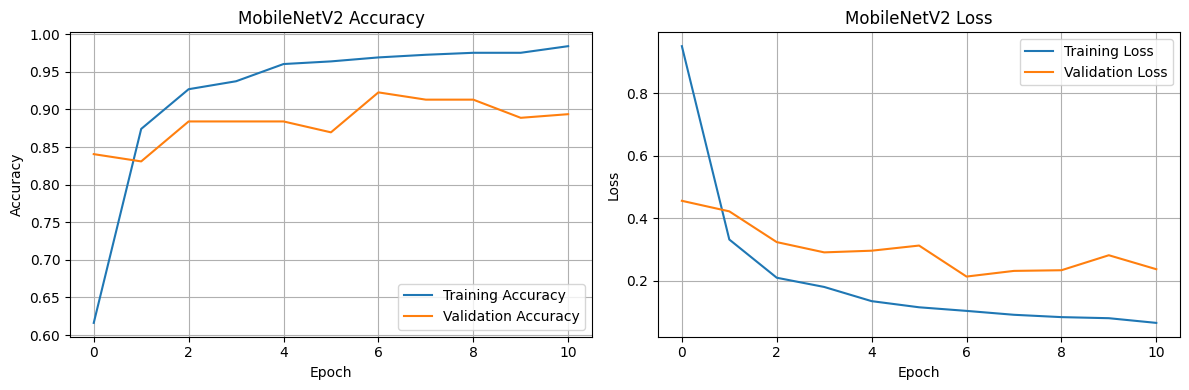

Grafik training berhasil disimpan.


In [37]:

import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Grafik Accuracy
axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("MobileNetV2 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Grafik Loss
axes[1].plot(
    history.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("MobileNetV2 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    output_dir / "training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafik training berhasil disimpan.")


Memuat model MobileNetV2 terbaik...
✅ Model berhasil dimuat!

Memulai evaluasi testing...
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.9415 - loss: 0.1676

HASIL EVALUASI TESTING
Test Accuracy: 94.15%
Test Loss: 0.1676

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

         Anthracnose     1.0000    0.7436    0.8529        39
Cercospora Leaf Spot     0.8333    1.0000    0.9091        50
          Fresh Leaf     0.9683    0.9839    0.9760        62
   Leaf Curl Disease     1.0000    0.9815    0.9907        54

            accuracy                         0.9415       205
           macro avg     0.9504    0.9272    0.9322       205
        weighted avg     0.9497    0.9415    0.9401       205



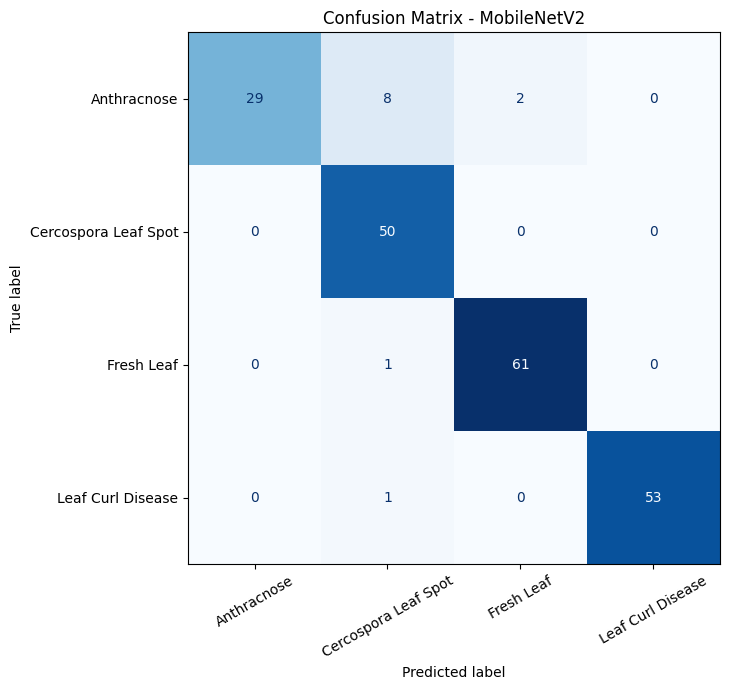


✅ Evaluasi selesai!
Classification Report: /content/drive/MyDrive/Chili-ML-Results/classification_report.txt
Confusion Matrix: /content/drive/MyDrive/Chili-ML-Results/confusion_matrix.png


In [38]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Folder penyimpanan hasil
output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)

model_path = output_dir / "mobilenetv2_best.keras"

class_names = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

# Pastikan pipeline testing dari langkah sebelumnya tersedia
assert "test_ds" in globals(), (
    "test_ds belum tersedia. "
    "Jalankan kembali sel Data Pipeline TensorFlow."
)

# Load model terbaik
print("Memuat model MobileNetV2 terbaik...")

best_model = tf.keras.models.load_model(
    model_path
)

print("✅ Model berhasil dimuat!")

# Evaluasi menggunakan testing dataset
print("\nMemulai evaluasi testing...")

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nHASIL EVALUASI TESTING")
print("=" * 50)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Prediksi pada data testing
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = best_model.predict(
        images,
        verbose=0
    )

    y_true.extend(labels.numpy().tolist())
    y_pred.extend(
        np.argmax(predictions, axis=1).tolist()
    )

# Classification Report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print("=" * 50)
print(report)

# Simpan classification report
report_path = output_dir / "classification_report.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(
        f"Test Accuracy: {test_accuracy * 100:.2f}%\n"
        f"Test Loss: {test_loss:.4f}\n\n"
    )
    f.write(report)

# Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30,
    colorbar=False
)

plt.title("Confusion Matrix - MobileNetV2")
plt.tight_layout()

cm_path = output_dir / "confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Evaluasi selesai!")
print("Classification Report:", report_path)
print("Confusion Matrix:", cm_path)


In [39]:

import json
import sys
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report

# Lokasi penyimpanan hasil ML di Google Drive
output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Menghasilkan metrik langsung dari evaluasi model
report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Metrik evaluasi final
metrics = {
    "model": "MobileNetV2",
    "python_version": sys.version.split()[0],
    "tensorflow_version": tf.__version__,
    "random_seed": 42,
    "dataset": {
        "total": 1548,
        "train": 1136,
        "validation": 207,
        "test": len(y_true),
        "classes": class_names
    },
    "evaluation": {
        "test_accuracy": round(float(test_accuracy), 4),
        "test_accuracy_percent": round(
            float(test_accuracy) * 100, 2
        ),
        "test_loss": round(float(test_loss), 4),
        "macro_precision": round(
            report_dict["macro avg"]["precision"], 4
        ),
        "macro_recall": round(
            report_dict["macro avg"]["recall"], 4
        ),
        "macro_f1_score": round(
            report_dict["macro avg"]["f1-score"], 4
        ),
        "weighted_f1_score": round(
            report_dict["weighted avg"]["f1-score"], 4
        ),
        "test_samples": len(y_true)
    },
    "per_class": {
        name: {
            "precision": round(report_dict[name]["precision"], 4),
            "recall": round(report_dict[name]["recall"], 4),
            "f1_score": round(report_dict[name]["f1-score"], 4),
            "support": int(report_dict[name]["support"])
        }
        for name in class_names
    }
}

# Simpan metrics.json
metrics_path = output_dir / "metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4, ensure_ascii=False)

print("Metrics berhasil disimpan!")
print("Lokasi:", metrics_path)

print("\nHASIL EVALUASI FINAL")
print("Test Accuracy:", metrics["evaluation"]["test_accuracy_percent"], "%")
print("Test Loss:", metrics["evaluation"]["test_loss"])
print("Macro F1:", metrics["evaluation"]["macro_f1_score"])


Metrics berhasil disimpan!
Lokasi: /content/drive/MyDrive/Chili-ML-Results/metrics.json

HASIL EVALUASI FINAL
Test Accuracy: 94.15 %
Test Loss: 0.1676
Macro F1: 0.9322


ANALISIS KESALAHAN MODEL
Total data testing: 205
Prediksi benar: 193
Prediksi salah: 12

DAFTAR KESALAHAN:
                   filename            actual            predicted  confidence
IMG_20250615_160831_923.jpg       Anthracnose           Fresh Leaf    0.358926
IMG_20250615_160853_933.jpg       Anthracnose           Fresh Leaf    0.755764
IMG_20250615_161128_465.jpg       Anthracnose Cercospora Leaf Spot    0.570926
IMG_20250615_161142_039.jpg       Anthracnose Cercospora Leaf Spot    0.743001
IMG_20250615_162131_580.jpg       Anthracnose Cercospora Leaf Spot    0.744068
IMG_20250615_162349_916.jpg       Anthracnose Cercospora Leaf Spot    0.612599
IMG_20250615_162907_098.jpg       Anthracnose Cercospora Leaf Spot    0.524968
IMG_20250615_163646_360.jpg       Anthracnose Cercospora Leaf Spot    0.698355
IMG_20250615_164050_647.jpg       Anthracnose Cercospora Leaf Spot    0.991820
IMG_20250615_164342_194.jpg       Anthracnose Cercospora Leaf Spot    0.862866
    IMG_20250615_165649.

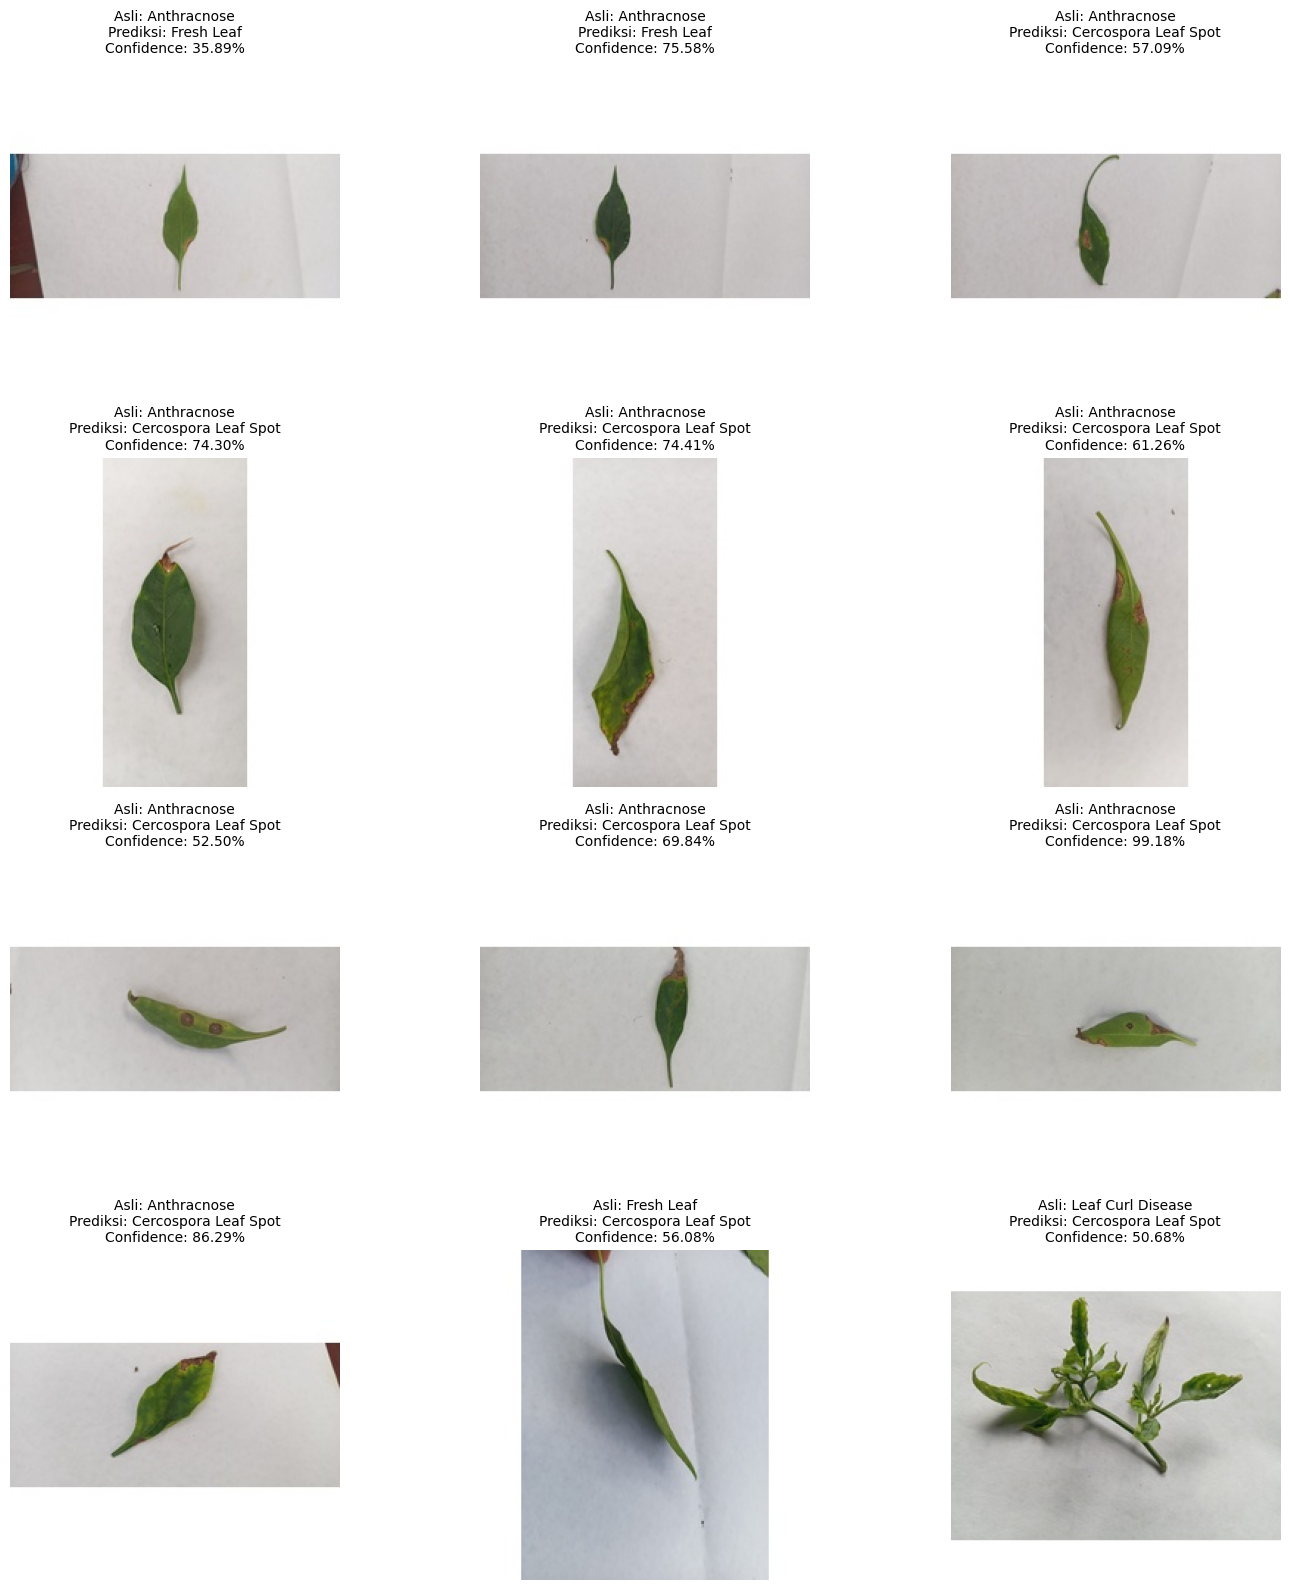


✅ Analisis kesalahan selesai!


In [40]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from math import ceil

output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)

processed_dir = Path("/content/chili_processed")

class_names = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

# Baca manifest V2
manifest = pd.read_csv(
    output_dir / "dataset_split_manifest_v2.csv"
)

test_df = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)

# Load model terbaik apabila diperlukan
if "best_model" not in globals():
    import tensorflow as tf

    best_model = tf.keras.models.load_model(
        output_dir / "mobilenetv2_best.keras"
    )

# Prediksi seluruh data testing tanpa shuffle
all_true = []
all_probabilities = []

for images, labels in test_ds:
    probabilities = best_model(
        images, training=False
    ).numpy()

    all_true.extend(labels.numpy())
    all_probabilities.extend(probabilities)

y_true = np.array(all_true)
probabilities = np.array(all_probabilities)
y_pred = np.argmax(probabilities, axis=1)

# Pastikan urutan label sesuai manifest
expected_labels = np.array([
    class_names.index(name)
    for name in test_df["class"]
])

assert len(y_true) == len(test_df)
assert np.array_equal(y_true, expected_labels), (
    "Urutan test_ds tidak sesuai manifest!"
)

# Temukan prediksi salah
wrong_indices = np.where(y_true != y_pred)[0]

print("ANALISIS KESALAHAN MODEL")
print("=" * 50)
print("Total data testing:", len(y_true))
print("Prediksi benar:", np.sum(y_true == y_pred))
print("Prediksi salah:", len(wrong_indices))

errors = []

for idx in wrong_indices:
    row = test_df.iloc[idx]

    errors.append({
        "filename": Path(row["relative_path"]).name,
        "actual": class_names[y_true[idx]],
        "predicted": class_names[y_pred[idx]],
        "confidence": float(
            probabilities[idx, y_pred[idx]]
        )
    })

df_errors = pd.DataFrame(errors)

print("\nDAFTAR KESALAHAN:")
print(df_errors.to_string(index=False))

# Simpan daftar kesalahan
df_errors.to_csv(
    output_dir / "prediction_errors.csv",
    index=False
)

# Tampilkan semua gambar yang salah
if len(wrong_indices) > 0:
    cols = 3
    rows = ceil(len(wrong_indices) / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(15, 4 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, wrong_indices):
        row = test_df.iloc[idx]

        image_path = (
            processed_dir / row["relative_path"]
        ).with_suffix(".jpg")

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"Asli: {class_names[y_true[idx]]}\n"
            f"Prediksi: {class_names[y_pred[idx]]}\n"
            f"Confidence: {probabilities[idx, y_pred[idx]]:.2%}",
            fontsize=10
        )

        ax.axis("off")

    for ax in axes[len(wrong_indices):]:
        ax.axis("off")

    plt.tight_layout()

    plt.savefig(
        output_dir / "prediction_errors.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

print("\n✅ Analisis kesalahan selesai!")


In [42]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from io import BytesIO
from google.colab import files
from pathlib import Path

# Lokasi model terbaik di Google Drive
model_path = Path(
    "/content/drive/MyDrive/Chili-ML-Results/"
    "mobilenetv2_best.keras"
)

class_names = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

# Load model yang sudah dilatih
model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("✅ Model MobileNetV2 berhasil dimuat!")
# False untuk Restart & Run All
# True jika ingin menguji gambar secara manual
RUN_MANUAL_DEMO = False

if RUN_MANUAL_DEMO:
    print("\nSilakan upload gambar daun cabai...")
    uploaded = files.upload()
else:
    print("\nDemo upload dilewati (mode otomatis).")
    uploaded = {}



for filename, file_content in uploaded.items():

    # Baca gambar
    with Image.open(BytesIO(file_content)) as source:
        img = ImageOps.exif_transpose(source)
        img = img.convert("RGB")

    original_img = img.copy()

    # Preprocessing sama seperti training
    img = ImageOps.pad(
        img,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        color=(255, 255, 255)
    )

    # Input float32 rentang 0-255
    # Normalisasi -1 sampai 1 sudah di dalam model
    image_array = np.asarray(
        img,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Prediksi
    predictions = model.predict(
        image_array,
        verbose=0
    )[0]

    predicted_index = int(
        np.argmax(predictions)
    )

    predicted_class = class_names[
        predicted_index
    ]

    confidence = float(
        predictions[predicted_index] * 100
    )

    # Tampilkan gambar
    plt.figure(figsize=(6, 5))
    plt.imshow(original_img)
    plt.axis("off")
    plt.title("Gambar yang Diuji")
    plt.show()

    # Tampilkan hasil
    print("\n" + "=" * 50)
    print("HASIL DETEKSI PENYAKIT DAUN CABAI")
    print("=" * 50)

    print("File:", filename)
    print("Prediksi:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    print("\nProbabilitas setiap kelas:")

    for name, probability in zip(
        class_names,
        predictions
    ):
        print(f"{name}: {probability * 100:.2f}%")

    print("\n✅ Prediksi selesai!")


✅ Model MobileNetV2 berhasil dimuat!

Demo upload dilewati (mode otomatis).


In [43]:

import tensorflow as tf
import numpy as np
from pathlib import Path
from PIL import Image

output_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)

keras_path = output_dir / "mobilenetv2_best.keras"
tflite_path = output_dir / "mobilenetv2_chili_float32.tflite"
labels_path = output_dir / "labels.txt"

class_names = [
    "Anthracnose",
    "Cercospora Leaf Spot",
    "Fresh Leaf",
    "Leaf Curl Disease"
]

# 1. Memuat model
print("Memuat model MobileNetV2...")

model = tf.keras.models.load_model(
    str(keras_path),
    compile=False
)

# 2. Konversi ke TensorFlow Lite
print("Memulai konversi TensorFlow Lite...")

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

tflite_path.write_bytes(tflite_model)

# 3. Menyimpan label kelas
labels_path.write_text(
    "\n".join(class_names) + "\n",
    encoding="utf-8"
)

# 4. Memeriksa model hasil konversi
interpreter = tf.lite.Interpreter(
    model_path=str(tflite_path)
)

interpreter.allocate_tensors()

input_info = interpreter.get_input_details()[0]
output_info = interpreter.get_output_details()[0]

print("\nHASIL KONVERSI")
print("=" * 50)

print("Model:", tflite_path.name)
print(
    "Ukuran model:",
    round(tflite_path.stat().st_size / (1024 ** 2), 2),
    "MB"
)
print("Input Shape:", input_info["shape"])
print("Input Type:", input_info["dtype"])
print("Output Shape:", output_info["shape"])
print("Output Type:", output_info["dtype"])
print("Jumlah kelas:", len(class_names))

# 5. Uji konsistensi hasil Keras dan TFLite
processed_dir = Path("/content/chili_processed")
sample_path = next(processed_dir.rglob("*.jpg"), None)

assert sample_path is not None, "Gambar sampel tidak ditemukan!"

with Image.open(sample_path) as img:
    sample = np.asarray(
        img.convert("RGB"), dtype=np.float32
    )[None, ...]

keras_pred = model(sample, training=False).numpy()

interpreter.set_tensor(
    input_info["index"], sample
)
interpreter.invoke()

tflite_pred = interpreter.get_tensor(
    output_info["index"]
)

difference = np.max(
    np.abs(keras_pred - tflite_pred)
)

print("\nVERIFIKASI PREDIKSI")
print("=" * 50)
print("Prediksi Keras:", class_names[np.argmax(keras_pred)])
print("Prediksi TFLite:", class_names[np.argmax(tflite_pred)])
print("Selisih probabilitas maksimum:", float(difference))

if (
    np.argmax(keras_pred) == np.argmax(tflite_pred)
    and difference < 0.01
):
    print("\n✅ Konversi dan pengujian awal berhasil!")
else:
    print("\n⚠️ Perlu pemeriksaan lebih lanjut.")


Memuat model MobileNetV2...
Memulai konversi TensorFlow Lite...
Saved artifact at '/tmp/tmp0iwn4ocf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  137078099375888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099378000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099377808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099377424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099373200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099375312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099373392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078330112336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099375504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137078099377616: Te

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



HASIL KONVERSI
Model: mobilenetv2_chili_float32.tflite
Ukuran model: 8.49 MB
Input Shape: [  1 224 224   3]
Input Type: <class 'numpy.float32'>
Output Shape: [1 4]
Output Type: <class 'numpy.float32'>
Jumlah kelas: 4

VERIFIKASI PREDIKSI
Prediksi Keras: Cercospora Leaf Spot
Prediksi TFLite: Cercospora Leaf Spot
Selisih probabilitas maksimum: 6.332993507385254e-07

✅ Konversi dan pengujian awal berhasil!


In [44]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive")

print("Google Drive berhasil diakses.")
print("\nFile dan folder terkait cabai:")

for item in sorted(drive_root.iterdir()):
    if "chili" in item.name.lower() or "cabai" in item.name.lower():
        print("-", item.name)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive berhasil diakses.

File dan folder terkait cabai:
- Chili Leaf Disease Dataset Annotated Smartphone Im.zip
- Chili Leaf Disease Original Dataset.zip
- Chili-Leaf-Disease-Classification.ipynb
- Chili-ML-Backup-Issue11-20261019-024758
- Chili-ML-Results
- Chili-Validation-Results
- chili_leaf_validation_training.ipynb


In [45]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("Python:", sys.version.split()[0])

packages = [
    "tensorflow",
    "numpy",
    "pandas",
    "Pillow",
    "matplotlib",
    "scikit-learn",
    "tqdm",
    "ImageHash"
]

for package in packages:
    try:
        print(f"{package}=={version(package)}")
    except PackageNotFoundError:
        print(f"{package}: belum terinstal")

Python: 3.13.15
tensorflow==2.21.0
numpy==2.1.3
pandas==2.2.3
Pillow==11.3.0
matplotlib==3.10.0
scikit-learn==1.6.1
tqdm==4.67.3
ImageHash==4.3.2


In [46]:

%pip install ImageHash

from importlib.metadata import version

print("ImageHash:", version("ImageHash"))
print("PyWavelets:", version("PyWavelets"))


ImageHash: 4.3.2
PyWavelets: 1.10.0


In [47]:

%pip install -r /content/requirements.txt

In [48]:

from pathlib import Path
from datetime import datetime
import shutil

# Folder hasil training lama
source_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)

# Buat folder backup baru
backup_dir = source_dir.parent / (
    "Chili-ML-Backup-Issue11-"
    + datetime.now().strftime("%Y%m%d-%H%M%S")
)

files_to_backup = [
    "mobilenetv2_best.keras",
    "mobilenetv2_chili_float32.tflite",
    "labels.txt"
]

if not source_dir.exists():
    print("Folder hasil training belum ditemukan.")
else:
    backup_dir.mkdir(parents=True, exist_ok=True)

    for filename in files_to_backup:
        source_file = source_dir / filename

        if source_file.exists():
            shutil.copy2(
                source_file,
                backup_dir / filename
            )
            print("BERHASIL BACKUP:", filename)
        else:
            print("FILE TIDAK DITEMUKAN:", filename)

    print("\nLokasi backup:", backup_dir)


BERHASIL BACKUP: mobilenetv2_best.keras
BERHASIL BACKUP: mobilenetv2_chili_float32.tflite
BERHASIL BACKUP: labels.txt

Lokasi backup: /content/drive/MyDrive/Chili-ML-Backup-Issue11-20261019-033446


In [49]:

from google.colab import drive
from pathlib import Path

# Hubungkan Google Drive
drive.mount("/content/drive")

# Periksa folder utama
drive_path = Path("/content/drive/MyDrive")

print("\nFolder terkait ChiliLeaf AI:")

for item in drive_path.iterdir():
    if any(word in item.name.lower() for word in [
        "chili", "model", "mobilenet", "ml"
    ]):
        print(
            "FOLDER:" if item.is_dir() else "FILE:",
            item.name
        )

# Periksa lokasi hasil training
result_path = drive_path / "Chili-ML-Results"

print("\nChili-ML-Results ditemukan:", result_path.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Folder terkait ChiliLeaf AI:
FILE: Chili Leaf Disease Dataset Annotated Smartphone Im.zip
FOLDER: Chili-ML-Results
FOLDER: Chili-Validation-Results
FILE: Chili Leaf Disease Original Dataset.zip
FILE: chili_leaf_validation_training.ipynb
FILE: Chili-Leaf-Disease-Classification.ipynb
FOLDER: Chili-ML-Backup-Issue11-20261019-024758
FOLDER: Chili-ML-Backup-Issue11-20261019-033446

Chili-ML-Results ditemukan: True


In [50]:

from pathlib import Path
import shutil

source = Path("/content/requirements.txt")
destination = Path(
    "/content/drive/MyDrive/Chili-ML-Results/requirements.txt"
)

if source.exists():
    shutil.copy2(source, destination)
    print("BERHASIL:", destination)
else:
    print("requirements.txt belum ditemukan di Colab.")


BERHASIL: /content/drive/MyDrive/Chili-ML-Results/requirements.txt


In [51]:

from pathlib import Path
import json

result_dir = Path(
    "/content/drive/MyDrive/Chili-ML-Results"
)

metrics_path = result_dir / "metrics.json"
curves_path = result_dir / "training_curves.png"

print("=== VERIFIKASI ISSUE #11 ===")

print("metrics.json:", metrics_path.exists())
print("training_curves.png:", curves_path.exists())

if metrics_path.exists():
    with open(metrics_path, "r", encoding="utf-8") as f:
        metrics = json.load(f)

    print("\n=== HASIL EVALUASI ===")
    print(
        "Test Accuracy:",
        metrics["evaluation"]["test_accuracy_percent"],
        "%"
    )
    print(
        "Test Loss:",
        metrics["evaluation"]["test_loss"]
    )
    print(
        "Macro F1:",
        metrics["evaluation"]["macro_f1_score"]
    )
    print(
        "Test Samples:",
        metrics["evaluation"]["test_samples"]
    )


=== VERIFIKASI ISSUE #11 ===
metrics.json: True
training_curves.png: True

=== HASIL EVALUASI ===
Test Accuracy: 94.15 %
Test Loss: 0.1676
Macro F1: 0.9322
Test Samples: 205
